# Visual Analytics Governance

When a company has hundreds of dashboards, the same KPI often has several definitions ("revenue" with or without tips, refunds, taxes), dashboards go stale, and nobody knows which one to trust. **Governance** defines metrics once, assigns owners, certifies trusted assets, tracks lineage and retires what nobody uses.

**After this lesson you can:**

1. Build a metric registry: one definition per metric, with owner and grain.
2. Compute every metric from the registry and detect conflicting definitions.
3. Inventory dashboards by usage and freshness, and decide what to certify or retire.
4. Draw a lineage graph from sources to dashboards and use it for impact analysis.

**Data:** NYC yellow taxi trips (January 2024) and a **synthetic** inventory of dashboards (usage logs are labelled as synthetic).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

COLS = ["tpep_pickup_datetime", "tpep_dropoff_datetime", "PULocationID", "DOLocationID", "trip_distance",
        "fare_amount", "tip_amount", "total_amount", "payment_type"]

def load_month(month: str) -> pd.DataFrame:
    """One month of NYC yellow taxi trips with the cleaning rules of M08 Lesson 08."""
    df = pd.read_parquet(datasets.taxi(month), columns=COLS)
    start = pd.Timestamp(month + "-01")
    dur = (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60
    ok = (df["tpep_pickup_datetime"].between(start, start + pd.offsets.MonthBegin(1), inclusive="left")
          & dur.between(1, 180) & df["trip_distance"].between(0.1, 100) & df["fare_amount"].between(3, 500))
    return df[ok].assign(duration_min=dur[ok])

zones = pd.read_csv(datasets.fetch("taxi_zone_lookup.csv"))

import networkx as nx

trips = load_month("2024-01")

## 1. The Problem: One Name, Several Numbers

Three teams report "revenue" for January 2024. Each definition is reasonable; together they produce three different numbers.

In [2]:
definitions = {
    "finance: total charged":            lambda d: d["total_amount"].sum(),
    "operations: fares only":            lambda d: d["fare_amount"].sum(),
    "marketing: fares + tips (card)":    lambda d: d["fare_amount"].sum() + d.loc[d["payment_type"] == 1, "tip_amount"].sum(),
}
conflict = pd.Series({name: f(trips) for name, f in definitions.items()}) / 1e6
print(conflict.round(2).to_string(), "(million USD)")
print(f"\nthe largest number is {100 * (conflict.max() / conflict.min() - 1):.0f}% higher than the smallest")

finance: total charged            78.01
operations: fares only            52.71
marketing: fares + tips (card)    62.23 (million USD)

the largest number is 48% higher than the smallest


## 2. A Metric Registry

A **metric registry** (or *semantic layer*) defines each metric once: name, description, formula, grain, filters, owner and status. Dashboards and reports read metrics from the registry instead of re-implementing them. Tools: dbt semantic layer / MetricFlow, Cube, LookML, Power BI semantic models; the idea is the same as in this small example.

In [3]:
import yaml

REGISTRY_YAML = """
metrics:
  gross_revenue:
    description: Everything charged to passengers (fare, surcharges, tolls, tips).
    expression: sum(total_amount)
    owner: finance
    status: certified
  fare_revenue:
    description: Metered fares only, without surcharges, tolls and tips.
    expression: sum(fare_amount)
    owner: operations
    status: certified
  trips:
    description: Number of cleaned trips.
    expression: count(*)
    owner: operations
    status: certified
  card_tip_rate:
    description: Card tips divided by card fares (cash tips are not recorded).
    expression: sum(tip_amount) / sum(fare_amount)
    filter: payment_type = 1
    owner: customer-experience
    status: draft
"""
registry = yaml.safe_load(REGISTRY_YAML)["metrics"]

import duckdb

def metric(name: str, by: str | None = None, df: pd.DataFrame = trips) -> pd.DataFrame:
    """Compute a registered metric, optionally grouped by a dimension, from its single definition."""
    m = registry[name]
    where = f" WHERE {m['filter']}" if "filter" in m else ""
    if by:
        sql = f"SELECT {by}, {m['expression']} AS {name} FROM df{where} GROUP BY {by} ORDER BY {by}"
    else:
        sql = f"SELECT {m['expression']} AS {name} FROM df{where}"
    return duckdb.sql(sql).df()                                  # DuckDB reads the DataFrame `df` in place

print(metric("gross_revenue"))
print(metric("card_tip_rate"))
print(metric("trips", by="payment_type"))

   gross_revenue
0   7.800649e+07
   card_tip_rate
0       0.226403
   payment_type    trips
0             0   113548
1             1  2292911
2             2   418498
3             3     9591
4             4    21221


Every report that asks for `gross_revenue` gets the same number, because there is only one definition. A change to a definition is a reviewed change in one file (Git), not a silent edit in one dashboard.

## 3. Dashboard Inventory: Certify, Fix or Retire

The inventory below is **synthetic**: 40 dashboards with owners, views in the last 90 days, last data refresh and the metrics they use. Rules turn it into actions.

action
certify                        19
migrate to registry metrics    13
fix refresh                     7
retire                          1


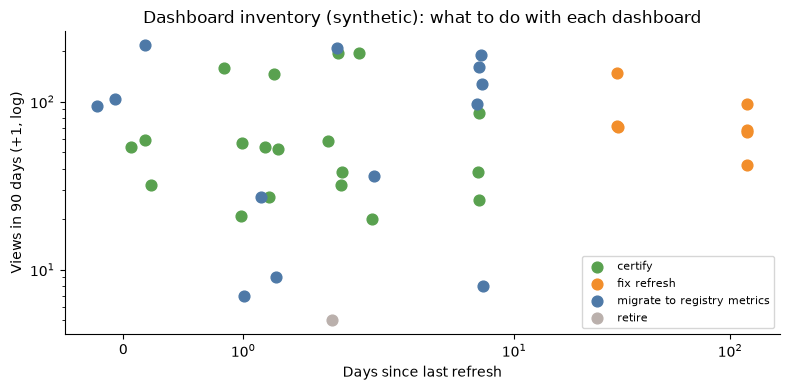

In [4]:
rng = np.random.default_rng(3)
n = 40
inventory = pd.DataFrame({
    "dashboard": [f"D{i:02d}" for i in range(n)],
    "owner": rng.choice(["finance", "operations", "marketing", "cx", None], n, p=[.25, .3, .2, .15, .1]),
    "views_90d": rng.negative_binomial(1, 0.02, n),
    "days_since_refresh": rng.choice([0, 1, 1, 2, 7, 30, 120], n),
    "uses_registry": rng.random(n) < 0.6,
})

def action(r):
    if r["owner"] is None:
        return "assign owner"
    if r["views_90d"] < 5:
        return "retire"
    if r["days_since_refresh"] > 7:
        return "fix refresh"
    if not r["uses_registry"]:
        return "migrate to registry metrics"
    return "certify"

inventory["action"] = inventory.apply(action, axis=1)
summary = inventory["action"].value_counts()
print(summary.to_string())

fig, ax = plt.subplots(figsize=(8, 4))
colors = {"certify": "#59A14F", "migrate to registry metrics": "#4E79A7", "fix refresh": "#F28E2B", "retire": "#BAB0AC",
          "assign owner": "#E15759"}
for act, part in inventory.groupby("action"):
    ax.scatter(part["days_since_refresh"] + rng.uniform(-0.3, 0.3, len(part)), part["views_90d"] + 1, s=60,
               color=colors[act], label=act)
ax.set(xscale="symlog", yscale="log", xlabel="Days since last refresh", ylabel="Views in 90 days (+1, log)",
       title="Dashboard inventory (synthetic): what to do with each dashboard")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 4. Lineage and Impact Analysis

**Lineage** records which sources feed which datasets, metrics and dashboards. Before you change a source column or a metric definition, lineage answers: *what will be affected?*

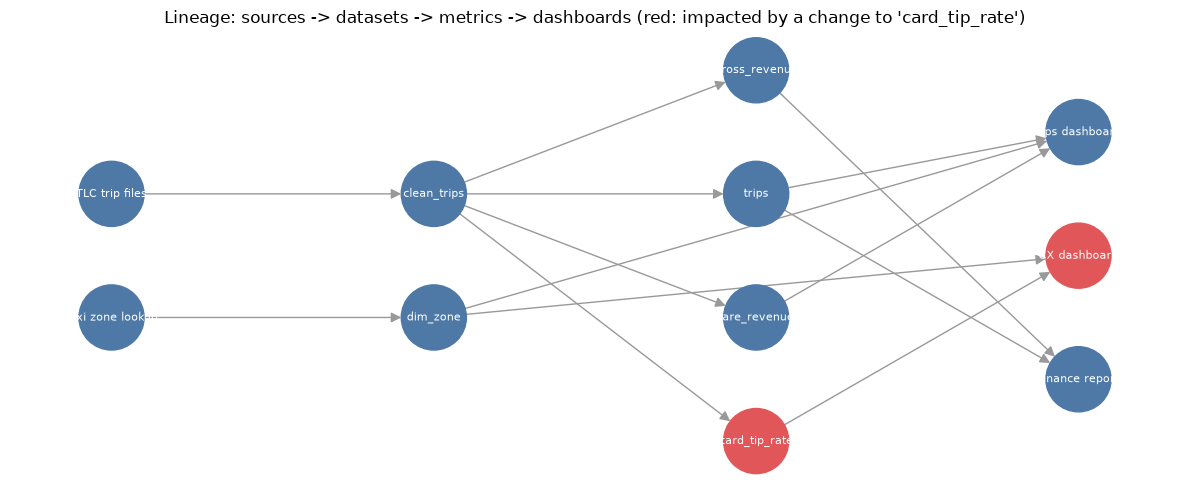

impact of changing card_tip_rate: ['CX dashboard']
everything the Finance report depends on: ['TLC trip files', 'clean_trips', 'gross_revenue', 'trips']


In [5]:
G = nx.DiGraph()
edges = [
    ("TLC trip files", "clean_trips"), ("taxi zone lookup", "dim_zone"),
    ("clean_trips", "gross_revenue"), ("clean_trips", "fare_revenue"), ("clean_trips", "trips"), ("clean_trips", "card_tip_rate"),
    ("dim_zone", "Ops dashboard"), ("trips", "Ops dashboard"), ("fare_revenue", "Ops dashboard"),
    ("gross_revenue", "Finance report"), ("trips", "Finance report"),
    ("card_tip_rate", "CX dashboard"), ("dim_zone", "CX dashboard"),
]
G.add_edges_from(edges)
layer = {"TLC trip files": 0, "taxi zone lookup": 0, "clean_trips": 1, "dim_zone": 1,
         "gross_revenue": 2, "fare_revenue": 2, "trips": 2, "card_tip_rate": 2,
         "Ops dashboard": 3, "Finance report": 3, "CX dashboard": 3}
nx.set_node_attributes(G, layer, "layer")
pos = nx.multipartite_layout(G, subset_key="layer")
changed = "card_tip_rate"
impacted = nx.descendants(G, changed) | {changed}
upstream = nx.ancestors(G, "Finance report")

fig, ax = plt.subplots(figsize=(12, 5))
node_colors = ["#E15759" if n in impacted else "#4E79A7" for n in G.nodes()]
nx.draw_networkx(G, pos, node_color=node_colors, node_size=2200, font_size=8, font_color="white", arrows=True,
                 arrowsize=15, edge_color="#999999", ax=ax)
ax.set_title(f"Lineage: sources -> datasets -> metrics -> dashboards (red: impacted by a change to '{changed}')")
ax.axis("off")
plt.tight_layout()
plt.show()
print("impact of changing card_tip_rate:", sorted(impacted - {changed}))
print("everything the Finance report depends on:", sorted(upstream))

## 5. Governance Roles and Processes

| Element | Practice |
| :--- | :--- |
| ownership | every metric and dashboard has a named owner |
| certification | trusted assets carry a "certified" badge; others are clearly "draft" or "personal" |
| change control | metric definitions change through reviewed pull requests, with release notes |
| freshness | data refresh is monitored; stale dashboards show a warning |
| lifecycle | unused dashboards are archived after a fixed period (for example 90 days without views) |
| access | permissions follow data classification (public, internal, confidential) |

*Insight: Governance is mostly about having one definition per metric, one owner per asset, and a visible signal of what is trusted. A small metric registry and a dashboard inventory with clear rules solve most "why are these numbers different?" questions.*

## Real-World Use Case or Analogy

A metric registry is like the **official dictionary of a language**: everybody can still write freely, but when two people disagree about what a word means, there is one reference. Certification is like a **seal on a product** that tells buyers it was checked.

Large companies run "metrics stores" and BI governance programmes because conflicting numbers in board meetings cost time and trust. Tools such as dbt's semantic layer, Looker's LookML and Power BI's certified semantic models put exactly these ideas into practice.